In [1]:
import os
import sys
import requests
import datetime as dt
import numpy as np
from dotenv import load_dotenv
from pathlib import Path
import requests
import pandas as pd
import talib as ta
import plotly.graph_objs as go

import ipywidgets as widgets
from ipywidgets import Dropdown, Text, Button, Output
from IPython.display import display

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.reques_api import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension

In [2]:
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()

#### WTIの時系列データを取得

In [3]:
wti = 'CL=F'
start = '1999-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')
response = request_api.update_commodity_timeseries_data(
    code=wti,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [4]:
wti_df = request_api.get_commodity_time_series_data(
    code=wti,
    market=None,
    start=start,
    end=end
)
wti_df.head()

取得件数: 6559


,id,commodity_id,commodity_code,commodity_market,date,open,high,low,close,adj_close,...,rci26,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,6530,2,CL=F,None,2000-08-23,32.049999,32.799999,31.950001,31.950001,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,6531,2,CL=F,None,2000-08-24,31.629999,32.240002,31.400000,31.900000,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,6532,2,CL=F,None,2000-08-25,32.049999,32.099998,31.320000,31.700001,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,6533,2,CL=F,None,2000-08-28,32.869999,32.919998,31.860001,32.040001,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,6534,2,CL=F,None,2000-08-29,32.720001,33.029999,32.560001,32.820000,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### S&P500の時系列データを取得

In [5]:
sp500 = '^GSPC'

response = request_api.update_stock_timeseries_data(
    code=sp500,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [6]:
sp_timeseries_df = request_api.get_stock_time_series_data(
    code=sp500,
    market=None,
    start=start,
    end=end
)
sp_timeseries_df.head()

取得件数: 7013


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1064856,^GSPC,None,1998-11-17,1139.319946,1151.709961,1129.670044,1135.869995,705200000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1064857,^GSPC,None,1998-11-18,1144.479980,1144.520020,1133.069946,1139.319946,652510000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1064858,^GSPC,None,1998-11-19,1152.609985,1155.099976,1144.420044,1144.479980,671000000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1064859,^GSPC,None,1998-11-20,1163.550049,1163.550049,1152.609985,1152.609985,721200000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1064860,^GSPC,None,1998-11-23,1188.209961,1188.209961,1163.550049,1163.550049,774100000,1147.165991,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### BKRの時系列データを取得

In [7]:
bkr = 'BKR'

response = request_api.update_stock_timeseries_data(
    code=bkr,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [8]:
bkr_timeseries_df = request_api.get_stock_time_series_data(
    code=bkr,
    market=None,
    start=start,
    end=end
)
bkr_timeseries_df

取得件数: 7013


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1111052,BKR,None,1998-11-17,8.964943,9.182275,8.774777,8.910610,1474800,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1111053,BKR,None,1998-11-18,8.693286,8.883452,8.638953,8.801952,3124000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1111054,BKR,None,1998-11-19,8.693286,8.747619,8.448787,8.693286,2924900,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1111055,BKR,None,1998-11-20,8.910611,9.073610,8.693279,8.937778,2119300,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1111056,BKR,None,1998-11-23,8.693286,8.992118,8.503120,8.937785,2271100,8.856282,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7008,1118060,BKR,None,2026-09-30,54.900002,56.470001,54.790001,56.189999,8378500,57.176000,...,56.841164,-13.263041,False,NaN,NaN,NaN,NaN,NaN,NaN,False
7009,1118061,BKR,None,2026-10-01,55.619999,56.070000,54.349998,54.549999,6572900,56.470000,...,56.405794,-24.583796,False,NaN,NaN,NaN,NaN,NaN,NaN,False
7010,1118062,BKR,None,2026-10-02,56.000000,56.320000,55.299999,55.529999,4222600,56.198000,...,56.093860,-35.469137,False,NaN,NaN,NaN,NaN,NaN,NaN,False
7011,1118063,BKR,None,2026-10-05,57.380001,57.970001,55.730000,56.000000,6663900,55.785999,...,55.837097,-44.399385,False,NaN,NaN,NaN,NaN,NaN,-84.17094,True


#### チャート

In [9]:
def stock_prices_and_oil_prices(
        code: str,
        name: str,
        start: str,
        end: str,
        df_sp: pd.DataFrame | None = None,
        df_wti: pd.DataFrame | None = None,
        #df_silver: pd.DataFrame | None = None,
    ):
    # /api/v1/time_series_data/stock/
    response = request_api.get_stock_time_series_data(
        code=code,
        market=None,
        start=start,
        end=end
    )
    df_stock = pd.DataFrame(response)

    # S&P500を統合
    if df_sp is not None:
        df_sp_tmp = df_sp.copy() if df_sp is not None else pd.DataFrame()
        if "date" not in df_sp_tmp.columns:
            df_sp_tmp = df_sp_tmp.reset_index()

        df_sp_tmp["date"] = pd.to_datetime(df_sp_tmp["date"])
        df_sp_tmp = df_sp_tmp.set_index("date")
        df_sp_tmp = df_sp_tmp.loc[start:end]

    # WTI原油価格を統合
    if df_wti is not None:
        df_wti_tmp = df_wti.copy() if df_wti is not None else pd.DataFrame()
        if "date" not in df_wti_tmp.columns:
            df_wti_tmp = df_wti_tmp.reset_index()
        df_wti_tmp["date"] = pd.to_datetime(df_wti_tmp["date"])
        df_wti_tmp = df_wti_tmp.set_index("date")
        df_wti_tmp = df_wti_tmp.loc[start:end]

    # 株価時系列データを整形
    df = df_stock.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date")
    df = df.loc[start:end]


    # インデックスを揃えて結合
    if df_sp is not None:
        df["MA50_SP"] = df_sp_tmp["ma50"].reindex(df.index)
        df["MA200_SP"] = df_sp_tmp["ma200"].reindex(df.index)
    if df_wti is not None:
        df["MA50_WTI"] = df_wti_tmp["ma50"].reindex(df.index)
        df["MA200_WTI"] = df_wti_tmp["ma200"].reindex(df.index)

    show_plot = ShowPlot()
    fig = show_plot.create_basic_chart(
        df=df.reset_index(),
        code=code,
        name=name,
        start=start,
        end=end,
        ma5=False,
        ma25=False,
        ma50=True,
        ma100=False,
        ma150=False,
        ma200=True,
    )
    # ★ 2つのY軸を定義（左：HYMC、右：SP500 & GOLD）
    fig.update_layout(
        yaxis=dict(
            title=f"{name} Price",
            side="left"
        ),
        yaxis2=dict(
            title="SP500 / WTI",
            overlaying="y",
            side="right"
        )
    )

    # --- SP500（右軸） ---
    if df_sp is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_SP"],
                name="SP_MA50",
                line={"color": "blue", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_SP"],
                name="SP_MA200",
                line={"color": "gray", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    # --- WTI（右軸） ---
    if df_wti is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_WTI"],
                name="WTI_MA50",
                line={"color": "orange", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_WTI"],
                name="WTI_MA200",
                line={"color": "yellow", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    return fig

In [10]:
name = "Baker Hughes"
start = dt.datetime(2025, 1, 1).strftime("%Y-%m-%d")
# グラフ領域の作成
fig = stock_prices_and_oil_prices(
    code=bkr,
    name=name,
    start=start,
    end=end,
    df_sp=None,
    df_wti=wti_df
)
fig.show()

取得件数: 648


In [11]:
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"{bkr}_{start}_{end}.png"
fig.write_image(str(output_path), width=1600, height=900, scale=2)
# 保存完了のメッセージを表示
print("saved:", output_path)

saved: /workspace/data/figures/BKR_2025-01-01_2026-10-07.png


#### 株価のみのチャート

In [12]:
name = "Baker Hughes"
start = dt.datetime(2025, 1, 1).strftime("%Y-%m-%d")
#end = dt.datetime(2026, 4, 17).strftime("%Y-%m-%d")
# グラフ領域の作成
fig = stock_prices_and_oil_prices(
    code=bkr,
    name=name,
    start=start,
    end=end,
    df_sp=None,
    df_wti=None
)
fig.show()

取得件数: 648


#### 時系列データを保存

In [13]:
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{bkr}_data_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"

df = bkr_timeseries_df.copy()
df = df.reset_index()
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")
df = df.loc['2026-01-01':end]
df.to_csv(output_path)
df.head()

,index,id,stock_code,stock_market,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
date,,,,,,,,,,,,,,,,,,,,,
2026-01-02,6822,1117874,BKR,None,46.634758,46.901865,44.863942,45.229979,4909900,45.138963,...,44.837785,-25.279604,False,NaN,NaN,NaN,NaN,NaN,NaN,True
2026-01-05,6823,1117875,BKR,None,48.544075,49.592715,47.752650,48.910108,14722600,45.966003,...,44.839290,-25.672330,False,NaN,NaN,-0.391235,NaN,NaN,NaN,False
2026-01-06,6824,1117876,BKR,None,48.850750,49.414640,48.009858,48.830964,7683300,46.727750,...,44.839256,-22.479297,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-07,6825,1117877,BKR,None,48.316540,49.246464,47.792221,48.949680,6844500,47.509284,...,44.847694,-19.115513,True,47.509284,NaN,NaN,NaN,NaN,NaN,False
2026-01-08,6826,1117878,BKR,None,49.661961,49.840032,48.326428,48.435249,6638900,48.071196,...,44.855750,-14.522326,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### Fibonacci Extension

{'fib_levels_down': {'1.000': np.float64(52.078415014237194),
  '1.272': np.float64(47.226014480753804),
  '1.382': np.float64(45.26364661794803),
  '1.618': np.float64(41.053475566837434)},
 'fib_levels_up': {'1.272': np.float64(74.77052339140951),
  '1.382': np.float64(76.73289125421529),
  '1.618': np.float64(80.94306230532588),
  '2.000': np.float64(87.75783070161505)},
 'swing_high': np.float64(69.91812285792612),
 'swing_low': np.float64(52.078415014237194),
 'df_with_fib':           date  index       id stock_code stock_market       open       high  \
 0   2026-01-02   6822  1117874        BKR         None  46.634758  46.901865   
 1   2026-01-05   6823  1117875        BKR         None  48.544075  49.592715   
 2   2026-01-06   6824  1117876        BKR         None  48.850750  49.414640   
 3   2026-01-07   6825  1117877        BKR         None  48.316540  49.246464   
 4   2026-01-08   6826  1117878        BKR         None  49.661961  49.840032   
 ..         ...    ...      ..

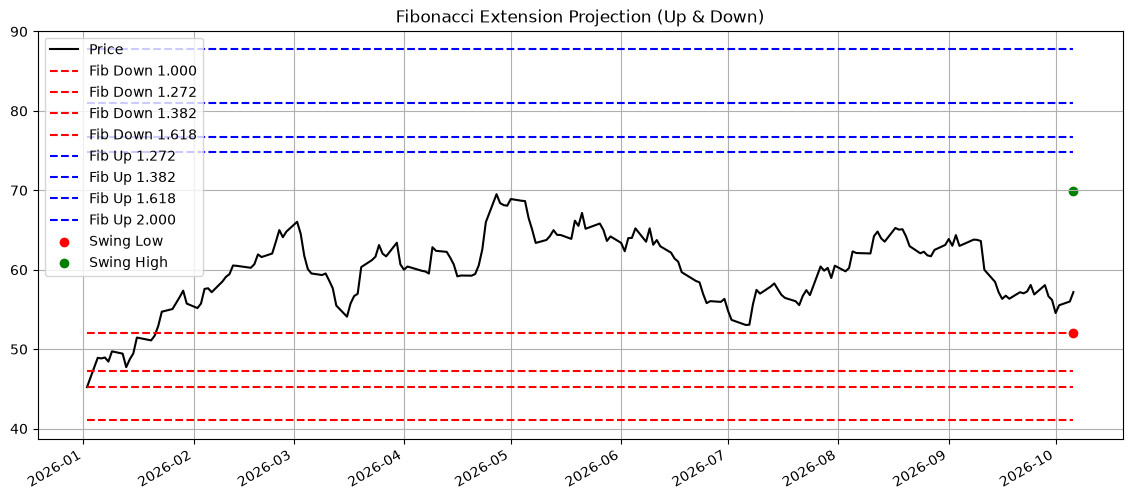

In [14]:
fib_result = fibonacci_extension.compute_fibonacci_extension(df.copy().reset_index())
fib_result

In [15]:
output_dir = Path("/workspace/data/figures/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{bkr}_fibonacci_extension_{dt.datetime.now().strftime('%Y-%m-%d')}.png"
fib_result["plot_obj"].savefig(output_path, dpi=300, bbox_inches="tight")

#### 財務データ

In [16]:
response = request_api.update_corp_finance_data(
    code=bkr,
    market=None
)
response

{'result': True}

In [17]:
bkr_financials_data = request_api.get_corp_financials_data(code=bkr, market=None)
bkr_balance_sheet_data = request_api.get_corp_balance_sheet_data(code=bkr, market=None)
bkr_cash_flow_data = request_api.get_corp_cash_flow_data(code=bkr, market=None)
bkr_earnings_data = request_api.get_corp_earnings_data(code=bkr, market=None)
bkr_quarterly_earnings_data = request_api.get_corp_quarterly_earnings_data(code=bkr, market=None)

In [18]:
# ４年分の財務データ
bkr_financials_data_df = pd.DataFrame(bkr_financials_data['results'])
# ４年分のバランスシート
bkr_balance_sheet_data_df = pd.DataFrame(bkr_balance_sheet_data['results'])
# ４年分のキャッシュフロー
bkr_cash_flow_data_df = pd.DataFrame(bkr_cash_flow_data['results'])
# ４年分の収益データ
bkr_earnings_data_df = pd.DataFrame(bkr_earnings_data['results'])
# ４年分の四半期収益データ
bkr_quarterly_earnings_data_df = pd.DataFrame(bkr_quarterly_earnings_data['results'])

In [19]:
"""
◆ 1. 株価・市場データ
• 現在株価（Price）
• 時価総額（Market Cap）
• 出来高（Volume）
• 52週高値・安値
• Beta（ボラティリティ指標）ß
"""
stock_prices_market_data.stock_prices_and_market_data(
    code=bkr,
    market=None,
    bs_df=bkr_balance_sheet_data_df
)

取得件数: 461
取得件数: 461
取得件数: 460
取得件数: 460
取得件数: 458
取得件数: 458
取得件数: 459
取得件数: 459
取得件数: 458
取得件数: 458


,close,market_cap,shares_outstanding,higher_rate_par_52_weeks,lower_rate_par_52_weeks,beta
0,13.749419,NaN,NaN,24.660419,7.674094,1.510443
1,21.267919,2.139553e+10,1.006000e+09,35.968052,16.457849,0.691020
2,30.651507,3.059020e+10,9.980000e+08,35.968052,18.693106,0.816580
3,27.900452,2.760822e+10,9.895258e+08,43.750603,24.219333,0.803476
4,29.872319,2.947722e+10,9.867739e+08,50.572102,28.921274,0.943657


In [20]:
"""
◆ 2. 財務データ（Financials）+ EPS（Earnings Per Share）+ PBR（Price-to-Book Ratio）
• 売上高（Revenue）
• 営業利益（Operating Income）
• 純利益（Net Income）
• EBITDA（企業による）
• 総資産（Total Assets）
• 総負債（Total Liabilities）
• 現金（Cash）
• 希釈EPS（Diluted EPS）
• 基本EPS（Basic EPS）
• 営業キャッシュフロー（Operating Cash Flow）
• フリーキャッシュフロー（Free Cash Flow）
"""
financial_df = financial.calc_financial(
    code = bkr,
    market = None,
)
financial_df.to_markdown()

取得件数: 6939


'|    | date                |      revenue |    earnings |   total_assets |   total_debt |   cash_and_cash_equivalents |    EBITDA |   operating_income |   basic_eps |   diluted_eps |   operating_cash_flow |   free_cash_flow |\n|---:|:--------------------|-------------:|------------:|---------------:|-------------:|----------------------------:|----------:|-------------------:|------------:|--------------:|----------------------:|-----------------:|\n|  0 | 2021-12-31 00:00:00 | nan          | nan         |   nan          |  nan         |                 nan         | 0         |        nan         |      nan    |        nan    |           nan         |      nan         |\n|  1 | 2022-12-31 00:00:00 |   2.1156e+10 |  -6.01e+08  |     3.4181e+10 |    6.658e+09 |                   2.488e+09 | 1.335e+09 |          1.89e+09  |       -0.61 |         -0.61 |             1.888e+09 |        8.99e+08  |\n|  2 | 2023-12-31 00:00:00 |   2.5506e+10 |   1.943e+09 |     3.6945e+10 |    6.021e+09 |  